<a href="https://colab.research.google.com/github/pratapsingh23/uk-road-accident-severity-prediction/blob/main/eda_and_insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importing required libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# Opening the cleaned parquet file:
df = pd.read_parquet('/content/drive/MyDrive/MINOR_PROJECT_FILES/cleaned_accident_data.parquet')

df.head(10)

,index,accident_severity,accident_date,latitude,light_conditions,district_area,longitude,number_of_casualties,number_of_vehicles,road_surface_conditions,...,weather_conditions,vehicle_type,year,month,day_of_week,is_weekend,season,is_covid,is_fatal,covid_period
0,200701BS64157,Serious,2019-06-05,51.506187,Darkness - lights lit,Kensington and Chelsea,-0.209082,1,2,Dry,...,Fine no high winds,Car,2019,6,Wednesday,False,Summer,Pre-COVID,0,Pre-COVID
1,200701BS65737,Serious,2019-07-02,51.495029,Daylight,Kensington and Chelsea,-0.173647,1,2,Wet or damp,...,Raining no high winds,Car,2019,7,Tuesday,False,Summer,Pre-COVID,0,Pre-COVID
2,200701BS66127,Serious,2019-08-26,51.517715,Darkness - lighting unknown,Kensington and Chelsea,-0.210215,1,3,Dry,...,Unknown,Taxi/Private hire car,2019,8,Monday,False,Summer,Pre-COVID,0,Pre-COVID
3,200701BS66128,Serious,2019-08-16,51.495478,Daylight,Kensington and Chelsea,-0.202731,1,4,Dry,...,Fine no high winds,Bus or coach (17 or more pass seats),2019,8,Friday,False,Summer,Pre-COVID,0,Pre-COVID
4,200701BS66837,Slight,2019-09-03,51.488576,Darkness - lights lit,Kensington and Chelsea,-0.192487,1,2,Dry,...,Unknown,Other vehicle,2019,9,Tuesday,False,Autumn,Pre-COVID,0,Pre-COVID
5,200701BS67159,Serious,2019-09-18,51.497750,Daylight,Kensington and Chelsea,-0.192556,2,3,Dry,...,Fine no high winds,Car,2019,9,Wednesday,False,Autumn,Pre-COVID,0,Pre-COVID
6,200701BS67207,Serious,2019-09-05,51.501405,Daylight,Kensington and Chelsea,-0.161577,1,2,Dry,...,Fine no high winds,Van / Goods 3.5 tonnes mgw or under,2019,9,Thursday,False,Autumn,Pre-COVID,0,Pre-COVID
7,200701BS67370,Fatal,2019-10-03,51.482260,Darkness - lights lit,Kensington and Chelsea,-0.179486,3,2,Dry,...,Fine no high winds,Car,2019,10,Thursday,False,Autumn,Pre-COVID,1,Pre-COVID
8,200701BS67515,Slight,2019-10-31,51.493319,Darkness - lights lit,Kensington and Chelsea,-0.173572,1,2,Dry,...,Fine no high winds,Car,2019,10,Thursday,False,Autumn,Pre-COVID,0,Pre-COVID
9,200701BS67543,Slight,2019-10-18,51.484539,Daylight,Kensington and Chelsea,-0.175651,1,2,Dry,...,Fine no high winds,Motorcycle over 125cc and up to 500cc,2019,10,Friday,False,Autumn,Pre-COVID,0,Pre-COVID


#**1. Accident Severity Distribution**

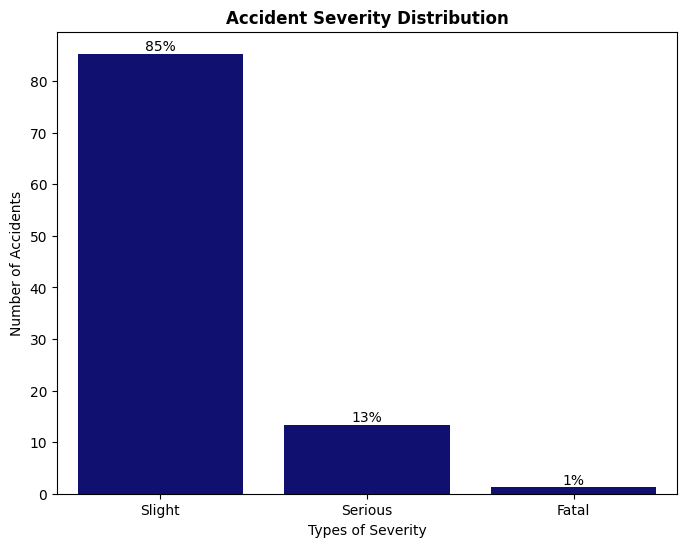

In [54]:
# Severity distribution:

order = df['accident_severity'].value_counts().index
fig, axes = plt.subplots(figsize=(8,6))
sns.countplot(
    data=df,
    x='accident_severity',
    order=order,
    stat='percent',
    color='navy',
    ax=axes
)

axes.set_title("Accident Severity Distribution", fontweight='bold')
axes.set_xlabel("Types of Severity")
axes.set_ylabel("Number of Accidents")

axes.bar_label(axes.containers[0], fmt='%1.f%%')
plt.show()

## Insight: Severity Distribution

The dataset is **heavily imbalanced**:

- **Slight**: about 85% of all accidents
- **Serious**: about 13%
- **Fatal**: only about 1%

Fatal accidents are rare, but they are the most important class to understand.
A model that always predicts "Slight" would be right about 85% of the time
without learning anything useful. Therefore, accuracy alone is misleading, and
the modelling stage will use **recall** and **F1-score** (especially for the
Fatal class), along with **class weights** or **resampling** to handle the imbalance.

#**2. Distribution of number of vehicles and number of casualites**

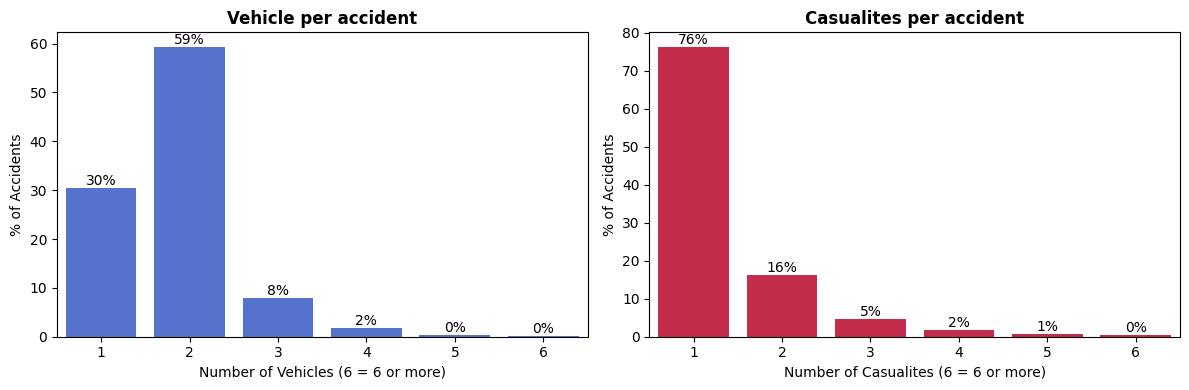

In [49]:
# number_of_casualties	number_of_vehicles distribution:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

# countplot of number of vehicles
sns.countplot(
    x=df['number_of_vehicles'].clip(upper=6),
    stat='percent',
    color='royalblue',
    ax=axes[0]
)

# countplot of number of casualites
sns.countplot(
    x=df['number_of_casualties'].clip(upper=6),
    stat='percent',
    color='crimson',
    ax=axes[1]
)

axes[0].set_title("Vehicle per accident", fontweight='bold')
axes[1].set_title("Casualites per accident", fontweight='bold')

axes[0].bar_label(axes[0].containers[0], fmt='%1.f%%')
axes[1].bar_label(axes[1].containers[0], fmt='%1.f%%')

axes[0].set_xlabel("Number of Vehicles (6 = 6 or more)")
axes[1].set_xlabel("Number of Casualites (6 = 6 or more)")
axes[0].set_ylabel("% of Accidents")
axes[1].set_ylabel("% of Accidents")

plt.tight_layout()
plt.show()

## Insight: Vehicles and Casualties per Accident

Most accidents involve only one or two vehicles and one or two casualties:

- **Vehicles per accident**: about 30% of accidents involve 1 vehicle and about 59% involve 2 vehicles.
- **Casualties per accident**: about 76% of accidents have 1 casualty and about 16% have 2 casualties.

Accidents with many vehicles or casualties are rare, but they do exist, so they
were kept in the data as genuine large-scale incidents.

#**3. Year wise accidents**

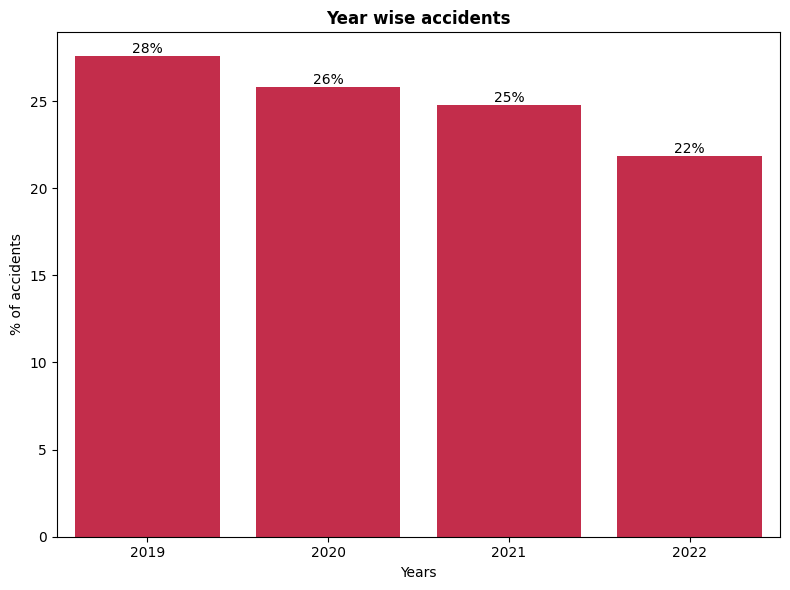

In [65]:
# Year wise accidents:

fig, ax = plt.subplots(figsize=(8,6))
sns.countplot(
    data=df[df['year']<=2022],
    x='year',
    color='crimson',
    stat='percent',
    ax=ax
)
ax.set_title("Year wise accidents", fontweight='bold')
ax.set_xlabel("Years")
ax.set_ylabel("% of accidents")
ax.bar_label(ax.containers[0], fmt='%1.f%%')
plt.tight_layout()
plt.show()

In [64]:
# Exact counts aur exact percentages check karne ke liye:
counts = df['year'].value_counts().sort_index()
percentages = df['year'].value_counts(normalize=True).sort_index() * 100

check_df = pd.DataFrame({'Count': counts, 'Percentage': percentages})
print(check_df)

       Count  Percentage
year                    
2019  182093   27.152447
2020  170571   25.434366
2021  163550   24.387443
2022  144418   21.534612
2023    3443    0.513396
2024    3352    0.499827
2025    3205    0.477907
